# 06 — Pemrosesan GFS → fitur per jam + gabung ke tabel (T18, T24.1–T24.2)

| Bagian | Isi | Checklist |
|---|---|---|
| 1 | Ekstrak titik terdekat + rata-rata 3×3 dari semua file run 00 UTC (cache per tahun) | T18.1–T18.2 |
| 2 | Daftar parameter yang ditemukan | — |
| 3 | De-averaging DSWRF & tutupan awan → blok 3 jam; interpolasi → per jam (DSWRF lewat k_c) | T18.3–T18.5 |
| 4 | Kelengkapan blok per tahun (termasuk 4 file 2016 yang hilang) | T24.2 |
| 5 | **Uji alignment GFS**: korelasi GHI_nwp vs NSRDB, maksimum harus di pergeseran 0 | T18.6 |
| 6 | Cek cepat kualitas GFS mentah (bias, per jam WIB) | — |
| 7 | Gabung ke tabel fitur + audit kebocoran (latensi GFS) | T18.7 |

Kode: `src/gfs_process.py`. Tes: `tests/test_gfs_process.py`.

## 0. Setup

In [1]:
import re, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import importlib, features as F, gfs_process as G
importlib.reload(F); importlib.reload(G)

CONFIG_PATH = ROOT / "configs" / "config.yaml"
txt = CONFIG_PATH.read_text()
if "gfs_latency_h" not in txt:     # asumsi: run 00 UTC lead 18–39 tersedia ±4,5 jam setelah inisialisasi
    txt = re.sub(r"(  gfs_run_utc:.*\n)", lambda m: m.group(1) + "  gfs_latency_h: 4.5          # jam setelah init sampai data tersedia (asumsi; verifikasi)\n", txt, count=1)
    CONFIG_PATH.write_text(txt)
CFG = yaml.safe_load(CONFIG_PATH.read_text())

GFS_DIR, INTERIM, PROC, FIG, RES = (ROOT / "data/raw/gfs", ROOT / "data/interim", ROOT / "data/processed",
                                    ROOT / "figures", ROOT / "results")
LAT, LON = CFG["location"]["lat"], CFG["location"]["lon"]
YEARS, ZMAX = CFG["data"]["years"], CFG["physics"]["zenith_max_deg"]
LAT_H = float(CFG["forecast"]["gfs_latency_h"])
print(f"Titik ({LAT}, {LON}) | latensi GFS diasumsikan {LAT_H} jam")

Titik (-6.8899, 107.61) | latensi GFS diasumsikan 4.5 jam


## 1. Ekstraksi (cache per tahun — jalankan ulang aman)

In [2]:
longs = []
for y in YEARS:
    cache = INTERIM / f"gfs_long_{y}.parquet"
    if cache.exists():
        longs.append(pd.read_parquet(cache)); print(f"{y}: dari cache"); continue
    files = G.run00_files(GFS_DIR / str(y))
    if not files:
        print(f"{y}: ⚠ tidak ada file run 00 di {GFS_DIR / str(y)}"); continue
    t0 = time.time()
    print(f"{y}: {len(files)} file …")
    lg = G.extract_files(files, LAT, LON)
    lg.to_parquet(cache)
    longs.append(lg)
    print(f"{y}: {len(lg):,} pesan dalam {time.time() - t0:.0f} dtk")
long = G.normalize_names(pd.concat(longs, ignore_index=True))   # cache lama ikut dipetakan ulang
g0 = long.iloc[0]
print(f"\nTitik grid terdekat: ({g0.grid_lat}, {g0.grid_lon}) | jumlah titik 3×3: {long['n_3x3'].unique()}")

2016: dari cache
2017: dari cache
2018: dari cache
2019: dari cache
2020: dari cache

Titik grid terdekat: (-7.0, 107.5) | jumlah titik 3×3: [9]


## 2. Parameter yang ditemukan

In [3]:
found = (long.groupby(["name", "step_type"])
         .agg(pesan=("init", "size"), lead=("end_h", lambda s: sorted(s.unique())))
         .reset_index())
display(found)
EXPECTED = {"dswrf_sfc", "tcdc_atm", "tcdc_low", "tcdc_mid", "tcdc_high", "tmp_2m", "rh_2m", "pwat_atm1", "cape_sfc"}
missing = EXPECTED - set(found["name"])
print("Semua parameter yang diminta ditemukan ✓" if not missing else f"⚠ Tidak ditemukan: {missing} — cek nama di tabel atas")

,name,step_type,pesan,lead
0,cape_sfc,instant,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
1,dswrf_sfc,avg,14611,"[18, 21, 24, 27, 30, 33, 36, 39]"
2,pwat_atm1,instant,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
3,rh_2m,instant,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
4,rh_atm1,instant,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
5,tcdc_atm,avg,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
6,tcdc_high,avg,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
7,tcdc_low,avg,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
8,tcdc_mid,avg,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"
9,tmp_2m,instant,14612,"[18, 21, 24, 27, 30, 33, 36, 39]"


Semua parameter yang diminta ditemukan ✓


## 3. Per jam (T18.3–T18.5)
`gfs_ghi_nwp` = k_c blok × GHI_cs Ineichen per jam (rata-rata 3 jamnya sama persis dengan blok GFS). Versi titik terdekat dan rata-rata 3×3 (`_3x3`) dibuat dua-duanya; pilihan final saat TK2.

In [4]:
hk = pd.read_parquet(INTERIM / "nsrdb_hourly_kc.parquet")
ghi_cs = hk["ghi_cs"]
t0 = time.time()
gh = pd.concat([G.to_hourly(long, ghi_cs, "v_point"), G.to_hourly(long, ghi_cs, "v_3x3", suffix="_3x3")], axis=1)
print(f"{len(gh):,} baris (init × jam), {gh.shape[1]} kolom, {time.time() - t0:.0f} dtk")
print(list(gh.columns))

40,190 baris (init × jam), 26 kolom, 39 dtk
['gfs_ghi_nwp', 'gfs_kc_nwp', 'gfs_dswrf_block', 'gfs_tcdc_atm', 'gfs_tcdc_high', 'gfs_tcdc_low', 'gfs_tcdc_mid', 'gfs_cape_sfc', 'gfs_pwat_atm1', 'gfs_rh_2m', 'gfs_rh_atm1', 'gfs_tmp_2m', 'gfs_tmp_sfc', 'gfs_ghi_nwp_3x3', 'gfs_kc_nwp_3x3', 'gfs_dswrf_block_3x3', 'gfs_tcdc_atm_3x3', 'gfs_tcdc_high_3x3', 'gfs_tcdc_low_3x3', 'gfs_tcdc_mid_3x3', 'gfs_cape_sfc_3x3', 'gfs_pwat_atm1_3x3', 'gfs_rh_2m_3x3', 'gfs_rh_atm1_3x3', 'gfs_tmp_2m_3x3', 'gfs_tmp_sfc_3x3']


## 4. Kelengkapan blok DSWRF per tahun (T24.2)

In [5]:
blk = G.deaverage(long[long["name"] == "dswrf_sfc"])
per_init = blk.groupby("init").size()
per_init.index = pd.to_datetime(per_init.index, utc=True)
inits = pd.Series(per_init.index.year, index=per_init.index)
comp = pd.DataFrame({"init": inits.groupby(inits).size(),
                     "init_lengkap_7_blok": (per_init == 7).groupby(inits).sum()})
comp["blok_hilang"] = (7 - per_init).clip(lower=0).groupby(inits).sum()
comp.index.name = "tahun init"
display(comp)
print("Init dengan blok kurang dari 7:", per_init[per_init < 7].to_dict())

,init,init_lengkap_7_blok,blok_hilang
tahun init,,,
2015,1,1,0
2016,366,363,4
2017,365,364,2
2018,365,365,0
2019,365,365,0
2020,365,365,0


Init dengan blok kurang dari 7: {Timestamp('2016-02-20 00:00:00+0000', tz='UTC'): 6, Timestamp('2016-02-22 00:00:00+0000', tz='UTC'): 5, Timestamp('2016-09-26 00:00:00+0000', tz='UTC'): 6, Timestamp('2017-12-19 00:00:00+0000', tz='UTC'): 5}


## 5. Uji alignment GFS (T18.6) — maksimum korelasi harus di pergeseran 0

-2    0.4685
-1    0.6962
 0    0.8078
 1    0.7057
 2    0.4490
Name: r, dtype: float64
T18.6 LULUS ✓


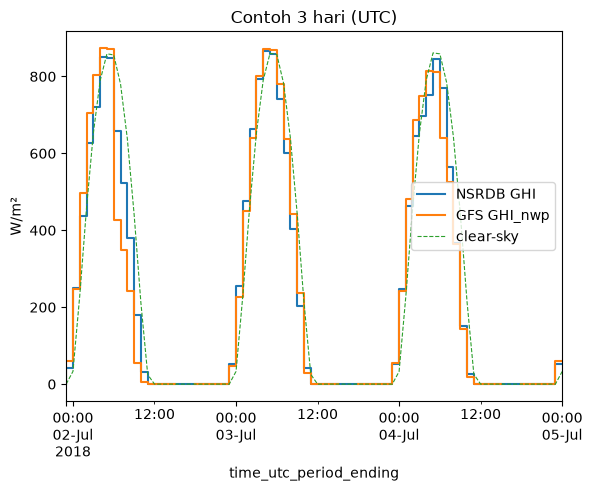

In [6]:
ghi_nwp_by_label = gh["gfs_ghi_nwp"].reset_index().groupby("label")["gfs_ghi_nwp"].first()
day = (hk["solar_zenith_angle"] < ZMAX) & hk["ghi"].notna()
day &= day.index.isin(ghi_nwp_by_label.index)
lag = G.alignment_by_shift(ghi_nwp_by_label, hk["ghi"], day)
print(lag.round(4))
T18_6 = int(lag.idxmax()) == 0
print("T18.6", "LULUS ✓" if T18_6 else "GAGAL ✗ — HENTIKAN, periksa valid_time / de-averaging (risiko #4)")

d0 = ghi_nwp_by_label.index[len(ghi_nwp_by_label) // 2].normalize()
w = slice(d0 - pd.Timedelta(hours=1), d0 + pd.Timedelta(days=3))
ax = hk.loc[w, "ghi"].plot(label="NSRDB GHI", drawstyle="steps-pre")
ghi_nwp_by_label.loc[w].plot(ax=ax, label="GFS GHI_nwp", drawstyle="steps-pre")
hk.loc[w, "ghi_cs"].plot(ax=ax, ls="--", lw=.8, label="clear-sky")
ax.set(title="Contoh 3 hari (UTC)", ylabel="W/m²"); ax.legend()
plt.savefig(FIG / "gfs_vs_nsrdb_example.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Kualitas GFS mentah (cek cepat, BUKAN hasil)
GFS dikenal cenderung melebihkan radiasi permukaan; ini justru alasan memakai ML sebagai post-processing.

Data latih, jam valid (n=9,751): bias GHI +84.8 W/m², RMSE 209.4 W/m², r = 0.729


,kc_obs,kc_nwp
jam WIB,,
7,1.271,1.413
8,0.818,0.942
9,0.800,0.941
10,0.788,0.940
11,0.744,0.857
12,0.693,0.854
13,0.641,0.853
14,0.604,0.651
15,0.576,0.650


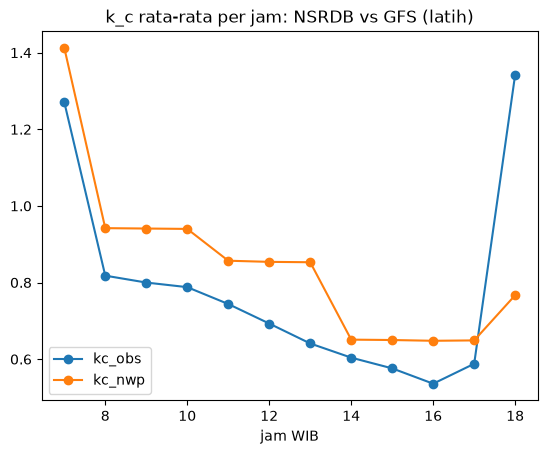

In [7]:
cmp = pd.DataFrame({"obs": hk["ghi"], "kc_obs": hk["kc"],
                    "nwp": ghi_nwp_by_label.reindex(hk.index),
                    "kc_nwp": gh["gfs_kc_nwp"].reset_index().groupby("label")["gfs_kc_nwp"].first().reindex(hk.index)})
valid = day & (hk["interp_frac"] <= 1/6 + 1e-9) & hk.index.year.isin(CFG["data"]["split"]["train"])
c = cmp[valid].dropna()
print(f"Data latih, jam valid (n={len(c):,}): bias GHI {(c.nwp - c.obs).mean():+.1f} W/m², "
      f"RMSE {np.sqrt(((c.nwp - c.obs) ** 2).mean()):.1f} W/m², r = {c.nwp.corr(c.obs):.3f}")
wib = (c.index.hour + 7) % 24
by_h = c.groupby(wib)[["kc_obs", "kc_nwp"]].mean().round(3)
by_h.index.name = "jam WIB"
display(by_h)
by_h.plot(marker="o", title="k_c rata-rata per jam: NSRDB vs GFS (latih)")
plt.savefig(FIG / "gfs_kc_diurnal.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Gabung ke tabel fitur + audit kebocoran (T18.7)

In [8]:
table = pd.read_parquet(PROC / "features_nsrdb.parquet")
full = G.merge_into_table(table, gh, latency_h=LAT_H, run_hour=int(CFG["forecast"]["gfs_run_utc"]))
rep = F.leakage_report(full)
display(rep[rep["fitur"].str.startswith("gfs_")].head(3))
F.assert_no_leakage(full)
print(f"✓ Tidak bocor: data GFS run 00 UTC D-1 tersedia {LAT_H} jam kemudian ≤ 05.00 UTC (12.00 WIB)")

gcols = [c for c in gh.columns]
na = full.loc[full["is_day"], gcols].isna().mean().mul(100).round(2)
print("% NaN kolom GFS pada jam siang:"); display(na.to_frame("% NaN"))

full.to_parquet(PROC / "features_all.parquet")
pd.DataFrame({"fitur": gcols, "kelompok": "NWP (GFS)",
              "aturan_waktu": f"run 00 UTC D-1, tersedia init + {LAT_H} jam"}).to_csv(RES / "feature_list_gfs.csv", index=False)
print(f"""
Salin ke decisions.md:
- {pd.Timestamp.today():%Y-%m-%d} | T18: GFS diproses dari {long['init'].nunique():,} run 00 UTC; titik grid ({g0.grid_lat}, {g0.grid_lon}) + rata-rata 3×3. DSWRF & TCDC di-de-average ke blok 3 jam (2·avg6 − avg3); DSWRF → per jam via k_c blok × GHI_cs Ineichen; variabel instan diinterpolasi linear. Blok 15–18 jam tidak bisa diturunkan (lead 15 tidak diunduh; malam). Alignment GFS: r maks pada pergeseran {int(lag.idxmax())} (r={lag.max():.3f}). Latensi GFS diasumsikan {LAT_H} jam (verifikasi). Bias GHI GFS mentah (latih) {(c.nwp - c.obs).mean():+.1f} W/m². | figures/gfs_vs_nsrdb_example.png, figures/gfs_kc_diurnal.png | Bab III, IV.1""")

,fitur,baris_bocor,maks_selisih_jam
9,gfs_ghi_nwp,0,-0.5
10,gfs_kc_nwp,0,-0.5
11,gfs_dswrf_block,0,-0.5


✓ Tidak bocor: data GFS run 00 UTC D-1 tersedia 4.5 jam kemudian ≤ 05.00 UTC (12.00 WIB)
% NaN kolom GFS pada jam siang:


,% NaN
gfs_ghi_nwp,0.06
gfs_kc_nwp,0.06
gfs_dswrf_block,0.06
gfs_tcdc_atm,0.03
gfs_tcdc_high,0.03
gfs_tcdc_low,0.03
gfs_tcdc_mid,0.03
gfs_cape_sfc,0.00
gfs_pwat_atm1,0.00
gfs_rh_2m,0.00



Salin ke decisions.md:
- 2026-11-27 | T18: GFS diproses dari 1,827 run 00 UTC; titik grid (-7.0, 107.5) + rata-rata 3×3. DSWRF & TCDC di-de-average ke blok 3 jam (2·avg6 − avg3); DSWRF → per jam via k_c blok × GHI_cs Ineichen; variabel instan diinterpolasi linear. Blok 15–18 jam tidak bisa diturunkan (lead 15 tidak diunduh; malam). Alignment GFS: r maks pada pergeseran 0 (r=0.808). Latensi GFS diasumsikan 4.5 jam (verifikasi). Bias GHI GFS mentah (latih) +84.8 W/m². | figures/gfs_vs_nsrdb_example.png, figures/gfs_kc_diurnal.png | Bab III, IV.1
